# Volumetric inverse design of a polarization-insensitive grating coupler

Optimize a **10 × 10 × 5 µm polymer volume** on glass with BeamZ to couple a **5.2 µm Gaussian beam tilted by 10°** into the TE₀₀ and TM₀₀ modes of a **2 × 2 µm waveguide**, at **1.55 µm**.

The objective is the mean coupling efficiency, $J=(\eta_{x\rightarrow\mathrm{TM}_{00}}+\eta_{y\rightarrow\mathrm{TE}_{00}})/2$. Density varies along all three dimensions; y-mirror symmetry ties mirrored voxels. The two forward/adjoint experiments share one density array. This local BeamZ workflow supports GPU execution.

**Run:** install this branch with `uv pip install -e '.[dev]' 'jax[cuda12]'` (omit CUDA on CPU), then select its Python kernel. The default `reference` profile uses the geometry above, 50 nm design pixels, 20 Adam updates at learning rate 0.5, 0.4 µm filter radius, and β = 1…20. Set `BEAMZ_GRATING_PROFILE=smoke` before launching Jupyter for a coarse, three-update execution check. Saved outputs identify the profile actually executed.

**Simulation setup:** the FDTD grid is uniform, with a 100 nm step in the reference profile; the density grid uses 50 nm pixels. We simulate the full y domain and enforce mirror symmetry on density. The beam propagates toward +x and −z. The source plane has a three-cell clearance from the design; its waist remains at that plane. The output monitor is at x = 6 µm, in the uniform waveguide before the absorber starts at x = 6.5 µm. The z domain is rounded outward for grid alignment. Mesh convergence and fabrication suitability require further validation.

In [1]:
import os
from pathlib import Path
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LightSource
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
import optax
from skimage.measure import marching_cubes

import beamz as bz
import beamz.optimization as opt

profile = os.environ.get("BEAMZ_GRATING_PROFILE", "reference")
if profile not in {"reference", "smoke"}:
    raise ValueError("BEAMZ_GRATING_PROFILE must be reference or smoke")
dx = (0.10 if profile == "reference" else 0.25) * bz.um
density_dx = (0.05 if profile == "reference" else 0.25) * bz.um
steps = 20 if profile == "reference" else 3
wavelength = 1.55 * bz.um
frequency = bz.LIGHT_SPEED / wavelength
run_time = 50 / (frequency / 10)
output_dir = Path("results/polarization_insensitive_grating") / profile
output_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})
colors = ("#2864b4", "#ca781c")
print(f"Profile: {profile} | devices: {jax.devices()} | FDTD: {dx/bz.um:g} µm | "
      f"density: {density_dx/bz.um:g} µm | {steps} updates | pulse run: {run_time*1e12:.3f} ps")

Profile: reference | devices: [CudaDevice(id=0)] | FDTD: 0.1 µm | density: 0.05 µm | 20 updates | pulse run: 2.585 ps


## Geometry and the two illumination experiments

Polymer has $n=1.53$, glass $n=1.444$, and the background is air. The glass top is at z = −2.5 µm, flush with the design bottom; the output guide occupies z = −2.5…−0.5 µm. Explicit TE and TM mode bases select the two target channels in the full simulation domain. The conic filter is spherical in 3D; projection sharpness increases during optimization. Filtering encourages smooth features but does not guarantee a fabrication limit or connectivity.

**Mode-label convention:** for the output guide propagating along x, TE₀₀ is Ey-dominated and TM₀₀ is Ez-dominated. The two experiments pair x-polarized illumination with TM₀₀ and y-polarized illumination with TE₀₀, using explicit polarization-aware mode selection.

In [2]:
rho_size = np.array([10, 10, 5]) * bz.um
size = np.array([15 * bz.um, 15 * bz.um,
                 2 * np.ceil((4 + 5 + 1.55) * bz.um / (2 * dx)) * dx])
polymer, glass = bz.Material(1.53**2), bz.Material(1.444**2)
geometry = bz.Design(background=bz.Material(1))
# Public geometry coordinates are centered in the simulation domain.
geometry += bz.Box(center=(0, 0, (-size[2]/2 - 2.5*bz.um)/2),
                   size=(size[0], size[1], size[2]/2 - 2.5*bz.um), material=glass)
geometry += bz.Box(center=(7.5*bz.um, 0, -1.5*bz.um),
                   size=(5*bz.um, 2*bz.um, 2*bz.um), material=polymer)


def mirror_y(density, pixel_size):
    return (density + jnp.flip(density, axis=1)) / 2


region = opt.TopologyDesignRegion(
    center=(0, 0, 0), size=tuple(rho_size), pixel_size=density_dx,
    eps_bounds=(1, 1.53**2), parameterization="volumetric",
    transformations=[mirror_y, opt.FilterProject(radius=0.4*bz.um), mirror_y],
    initialization_spec=opt.RandomInitializationSpec(seed=42),
)
pulse = bz.GaussianPulse(freq0=frequency, fwidth=frequency/10)
source_z = (2.5*bz.um + 3*dx)
beam = bz.GaussianBeamSource(
    center=(0, 0, source_z), size=(13*bz.um, 13*bz.um),
    source_time=pulse, direction="-z", angle_theta=np.deg2rad(10),  # Propagation toward +x and −z.
    waist_radius=2.6*bz.um, power=1,
)


def make_experiment(pol_angle, mode_polarization):
    output = bz.ModeMonitor(
        center=(6*bz.um, 0, -1.5*bz.um), size=(0, 6*bz.um, 6*bz.um),
        freqs=[frequency], name="output",
        mode_spec=bz.ModeSpec(num_modes=1, polarization=mode_polarization),
    )
    simulation = bz.Simulation(
        design=geometry, domain=tuple(size), resolution=dx, run_time=run_time,
        sources=[beam.updated_copy(pol_angle=pol_angle)], monitors=[output],
        boundaries=[bz.PML(thickness=1*bz.um, formulation="cpml")],
    )
    return opt.InverseDesign(simulation=simulation, design_region=region,
                             gradient_backend="adjoint")


experiments = [make_experiment(0, "tm"), make_experiment(np.pi/2, "te")]
params = jnp.asarray(region.initial_parameters)
print(f"Density shape (z, y, x): {params.shape}; {params.size:,} parameters")

Density shape (z, y, x): (100, 200, 200); 4,000,000 parameters


## Inspect a real volume

The middle xy, xz, and yz slices reveal variation along z. The surface panel renders the density = 0.5 boundary with a y ≥ 0 cutaway to expose the interior; it is a visualization of the continuous density, not a verified printable solid. Rendering may sample every second voxel on the fine grid, without changing the simulation.

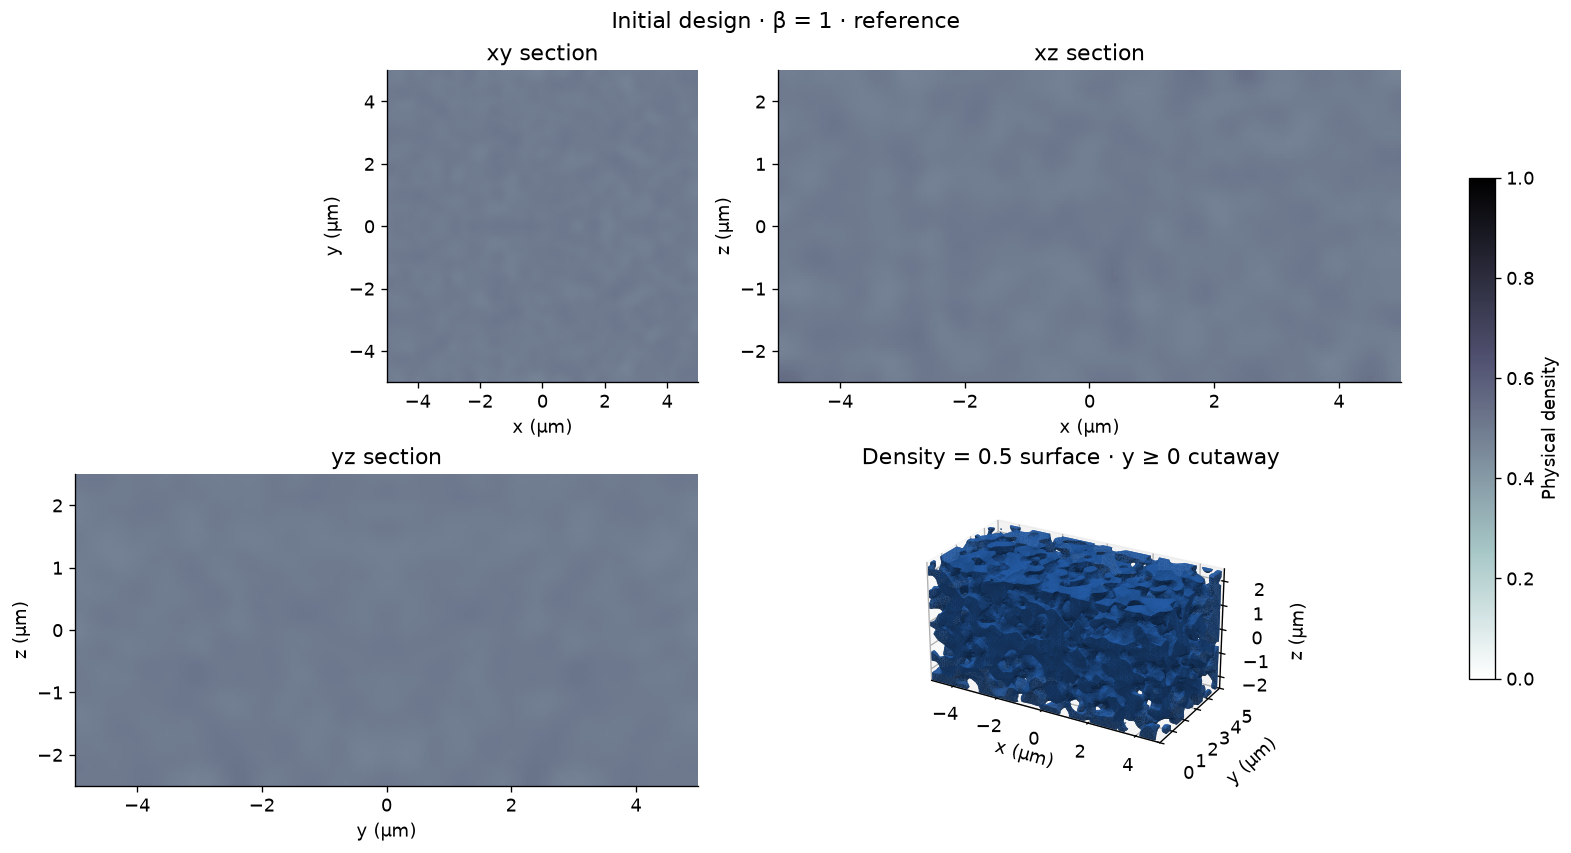

In [3]:
def show_density(parameters, beta, title):
    density = np.asarray(region.material_density(parameters, beta=beta))
    fig = plt.figure(figsize=(13, 7), layout="constrained")
    axes = [fig.add_subplot(2, 2, i) for i in (1, 2, 3)]
    nz, ny, nx = density.shape
    slices = [density[nz//2], density[:, ny//2], density[:, :, nx//2]]
    extents = [(-5, 5, -5, 5), (-5, 5, -2.5, 2.5), (-5, 5, -2.5, 2.5)]
    for ax, values, extent, labels in zip(axes, slices, extents, [("x", "y"), ("x", "z"), ("y", "z")]):
        image = ax.imshow(values, origin="lower", extent=extent, vmin=0, vmax=1, cmap="bone_r")
        ax.set(xlabel=f"{labels[0]} (µm)", ylabel=f"{labels[1]} (µm)", title=f"{labels[0]}{labels[1]} section")
    fig.colorbar(image, ax=axes, shrink=0.7, label="Physical density")
    ax = fig.add_subplot(2, 2, 4, projection="3d")
    stride = 2 if density.shape[-1] > 100 else 1
    cutaway = density.copy()
    cutaway[:, :ny//2, :] = 0  # Rendering only: expose the symmetry-plane interior.
    sampled = np.pad(cutaway[::stride, ::stride, ::stride], 1)
    if sampled.max() > 0.5:
        verts, faces, _, _ = marching_cubes(sampled, level=0.5, step_size=1)
        verts = ((verts - 1)*stride + 0.5) * density_dx / bz.um
        verts -= np.array([2.5, 5, 5])
        surface = Poly3DCollection(verts[faces][:, :, ::-1], facecolors=colors[0],
                                   edgecolor="none", shade=True, lightsource=LightSource(315, 45),
                                   rasterized=True)
        ax.add_collection3d(surface)
    ax.set(xlim=(-5, 5), ylim=(0, 5), zlim=(-2.5, 2.5), xlabel="x (µm)",
           ylabel="y (µm)", zlabel="z (µm)", title="Density = 0.5 surface · y ≥ 0 cutaway")
    ax.set_box_aspect((2, 1, 1))
    ax.view_init(elev=25, azim=-60)
    fig.suptitle(f"{title} · β = {beta:g} · {profile}")
    return fig


show_density(params, beta=1, title="Initial design");

## Shared-density objective and gradient check

Amplitudes are normalized by the Gaussian pulse spectrum and projected into power-normalized output modes. Divide $|a|^2$ by the fixed incident power (1 W here) to obtain coupling efficiency. The adjoint retains design-region electric DFTs rather than the entire time history and checks that both forward and adjoint fields decay.

The directional finite-difference check below probes the **combined two-polarization objective**, including symmetry, filtering, projection, resampling, and the Yee material map. A second run-time check near the end tests whether truncated transients materially change the answer.

In [4]:
def coupling_efficiencies(parameters, beta):
    return jnp.stack([
        opt.ModePower("output")(experiment.to_simulation_data(parameters, beta=beta))
        for experiment in experiments
    ])


def objective(parameters, beta):
    efficiencies = coupling_efficiencies(parameters, beta)
    return jnp.mean(efficiencies), efficiencies


evaluate = jax.value_and_grad(objective, has_aux=True)
(initial_value, initial_ce) = objective(params, 1.0)
check_params = 0.1 + 0.8*params  # Keep finite-difference probes inside [0, 1].
(_, _), gradient = evaluate(check_params, 1.0)
direction = gradient / jnp.linalg.norm(gradient)
h = 0.01
finite_difference = (objective(check_params+h*direction, 1.0)[0] - objective(check_params-h*direction, 1.0)[0]) / (2*h)
adjoint_derivative = jnp.vdot(gradient, direction).real
relative_error = float(abs(finite_difference-adjoint_derivative) / abs(adjoint_derivative))
assert np.isfinite(gradient).all() and np.linalg.norm(gradient) > 0
assert relative_error < 0.02, f"Gradient check error: {relative_error:.4%}"
print(f"Initial CE: x→TM {float(initial_ce[0]):.4%}, y→TE {float(initial_ce[1]):.4%}")
print(f"Directional derivative: adjoint {float(adjoint_derivative):.6g}, "
      f"finite difference {float(finite_difference):.6g}; relative error {relative_error:.4%}")

Initial CE: x→TM 0.0001%, y→TE 0.0003%
Directional derivative: adjoint 6.79382e-06, finite difference 6.79378e-06; relative error 0.0005%


## Twenty Adam updates with projection continuation

The reference learning rate is 0.5 and β increases by one each update. The history records **pre-update** efficiencies at that iteration's β; the final density is evaluated separately at the final β. Each checkpoint is a portable numerical snapshot (density, history, and settings), not a serialized Python object. This compact loop combines both simulations explicitly.

In [5]:
optimizer = optax.adam(learning_rate=0.5)
optimizer_state = optimizer.init(params)
initial_params = np.asarray(params).copy()
history = []
start = time.perf_counter()
for step in range(steps):
    beta = float(step + 1)
    (score, efficiencies), gradient = evaluate(params, beta)
    if not np.isfinite(gradient).all():
        raise FloatingPointError("Nonfinite design gradient")
    updates, optimizer_state = optimizer.update(-gradient, optimizer_state, params)
    params = jnp.clip(optax.apply_updates(params, updates), 0, 1)
    history.append([step, beta, *np.asarray(efficiencies)])
    np.savez_compressed(output_dir / "design.npz", density=np.asarray(params),
                        initial_density=initial_params, history=np.array(history),
                        profile=profile, fdtd_dx=dx, density_dx=density_dx, beta=beta)
    print(f"{step+1:2d}/{steps} · β={beta:g} · x→TM {float(efficiencies[0]):6.2%} · "
          f"y→TE {float(efficiencies[1]):6.2%} · mean {float(score):6.2%}")

final_beta = float(steps)
final_ce = np.asarray(coupling_efficiencies(params, final_beta))
history = np.asarray(history)
np.savez_compressed(output_dir / "design.npz", density=np.asarray(params),
                    initial_density=initial_params, history=history, final_ce=final_ce,
                    profile=profile, fdtd_dx=dx, density_dx=density_dx, beta=final_beta)
print(f"Final CE: x→TM {final_ce[0]:.2%}, y→TE {final_ce[1]:.2%}; "
      f"mean {final_ce.mean():.2%} | elapsed {(time.perf_counter()-start)/60:.1f} min")

 1/20 · β=1 · x→TM  0.00% · y→TE  0.00% · mean  0.00%


 2/20 · β=2 · x→TM  3.79% · y→TE 16.25% · mean 10.02%


 3/20 · β=3 · x→TM 19.88% · y→TE 22.24% · mean 21.06%


 4/20 · β=4 · x→TM 23.39% · y→TE 19.21% · mean 21.30%


 5/20 · β=5 · x→TM 33.29% · y→TE 32.76% · mean 33.02%


...

17/20 · β=17 · x→TM 66.86% · y→TE 69.67% · mean 68.27%


18/20 · β=18 · x→TM 67.70% · y→TE 70.29% · mean 69.00%


19/20 · β=19 · x→TM 69.03% · y→TE 70.46% · mean 69.74%


20/20 · β=20 · x→TM 69.51% · y→TE 70.84% · mean 70.17%


Final CE: x→TM 69.95%, y→TE 71.82%; mean 70.88% | elapsed 37.7 min


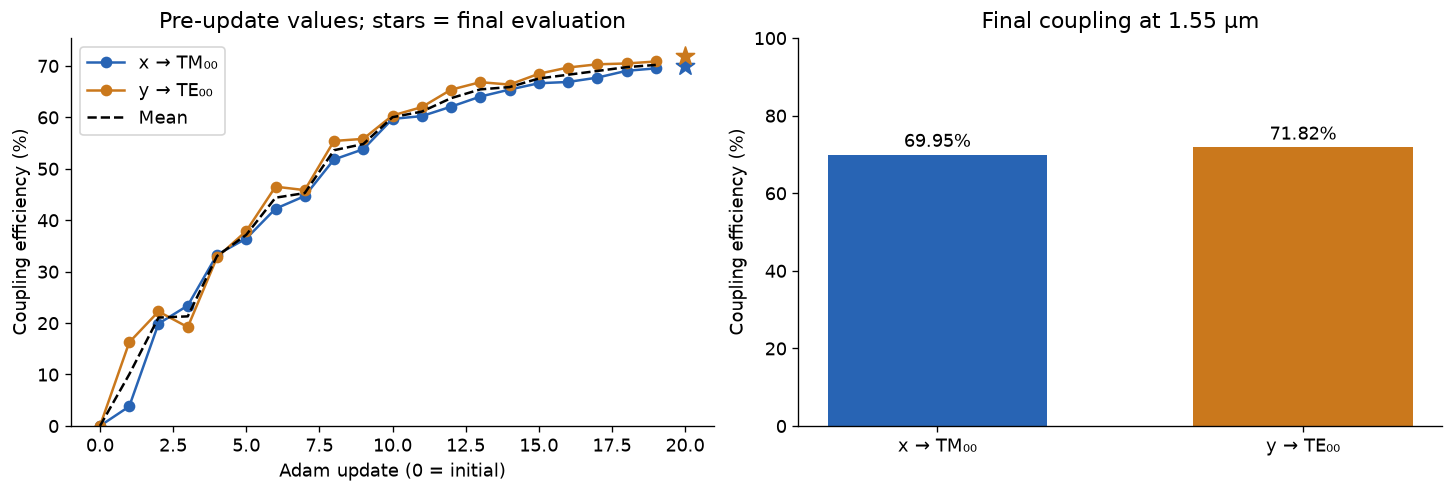

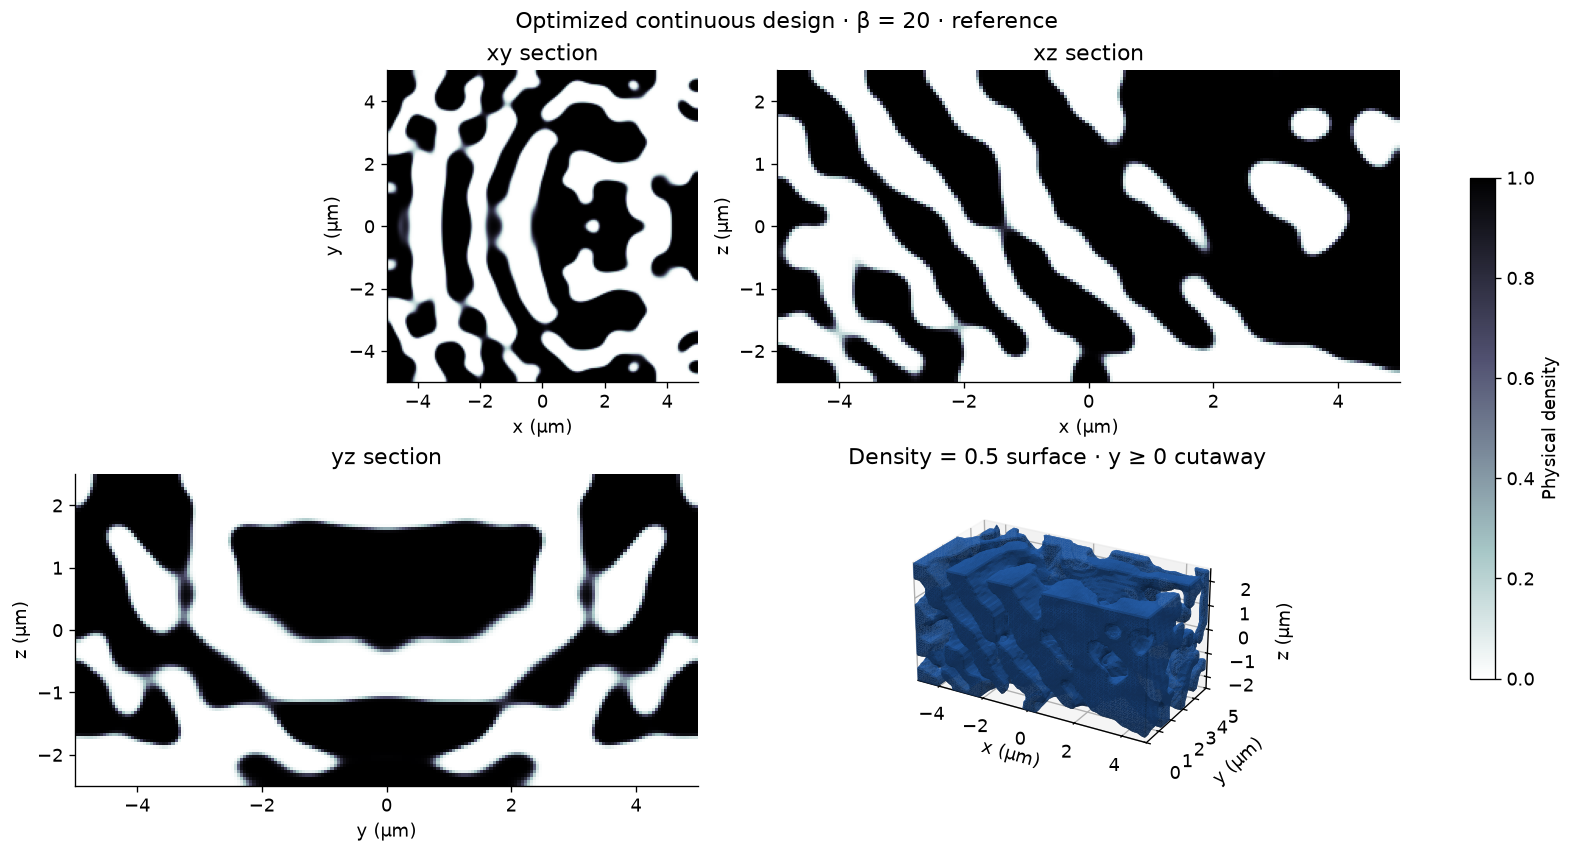

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for index, label in enumerate(("x → TM₀₀", "y → TE₀₀")):
    axes[0].plot(history[:, 0], 100*history[:, index+2], "o-", color=colors[index], label=label)
    axes[0].scatter([steps], [100*final_ce[index]], marker="*", s=130, color=colors[index])
axes[0].plot(history[:, 0], 50*(history[:, 2]+history[:, 3]), "k--", label="Mean")
axes[0].set(xlabel="Adam update (0 = initial)", ylabel="Coupling efficiency (%)",
            title="Pre-update values; stars = final evaluation", ylim=(0, None))
axes[0].legend()
axes[1].bar([0, 1], 100*final_ce, color=colors, width=0.6)
axes[1].set(xticks=[0, 1], xticklabels=["x → TM₀₀", "y → TE₀₀"],
            ylabel="Coupling efficiency (%)", title="Final coupling at 1.55 µm", ylim=(0, 100))
for index, efficiency in enumerate(final_ce):
    axes[1].text(index, 100*efficiency+2, f"{efficiency:.2%}", ha="center")
fig.savefig(output_dir / "convergence.png")
show_density(params, final_beta, "Optimized continuous design").savefig(output_dir / "density.png");

## Broadband validation and electric-field sections

Run ordinary BeamZ simulations on the final continuous-density material grid. Record **21 wavelengths from 1.50 to 1.60 µm**, and xy/xz electric-field sections at 1.55 µm. Coupling efficiencies use the same TE/TM definitions as optimization; the polarization-dependent loss is $10\log_{10}(\eta_{\max}/\eta_{\min})$. Maximizing the mean does not itself force the channels to be equal, so we report both and their imbalance.

PDL at 1.55 µm: 0.115 dB


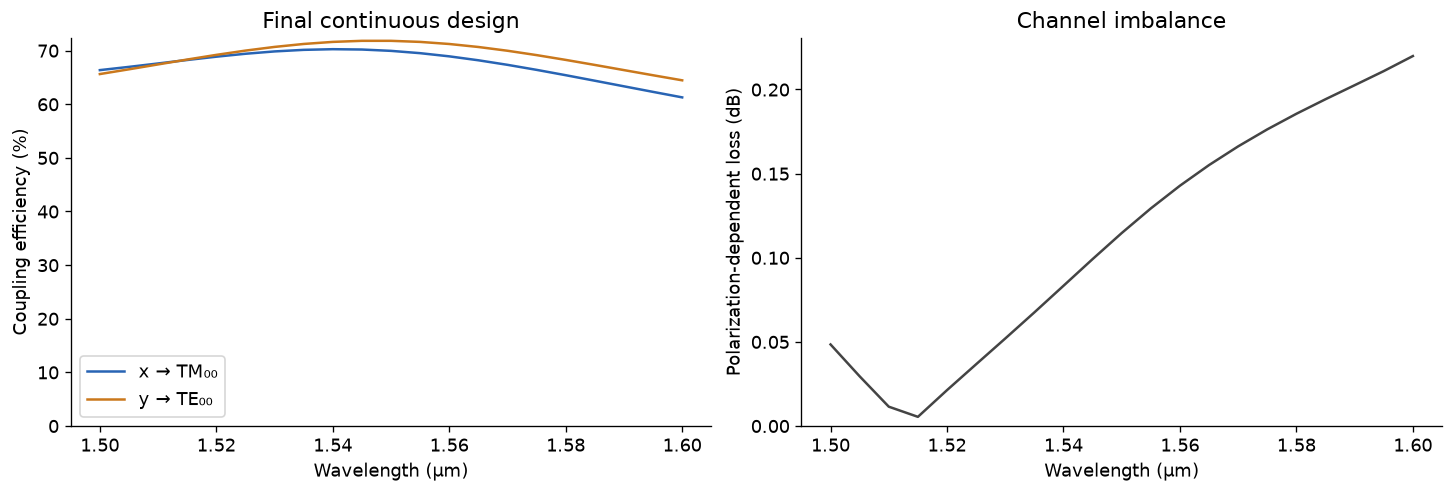

In [7]:
wavelengths = np.linspace(1.50, 1.60, 21) * bz.um
validation = []
for experiment in experiments:
    simulation = experiment.to_simulation(params, beta=final_beta)
    # Ordinary simulations keep normalized internal device coordinates.
    monitor = simulation.monitors[0]
    center = np.asarray(experiment.simulation.coordinate_offset)
    xy = bz.FieldMonitor(center=tuple(center + np.array([0, 0, -1.5])*bz.um),
                          size=(13*bz.um, 13*bz.um, 0), freqs=[frequency], name="xy",
                          fields=["Ex", "Ey", "Ez"])
    xz = bz.FieldMonitor(center=tuple(center), size=(13*bz.um, 0, 8*bz.um),
                          freqs=[frequency], name="xz", fields=["Ex", "Ey", "Ez"])
    simulation = simulation.updated_copy(monitors=[monitor.updated_copy(freqs=bz.LIGHT_SPEED/wavelengths), xy, xz])
    validation.append(simulation.run(backend="jax", performance=False))

spectra = np.stack([
    np.abs(result.mode("output").amps.sel(direction="+", mode_index=0).values)**2
    / result.launched_power(0) for result in validation
])
np.testing.assert_allclose(spectra[:, 10], final_ce, rtol=0.01, atol=1e-5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for index, label in enumerate(("x → TM₀₀", "y → TE₀₀")):
    axes[0].plot(wavelengths/bz.um, 100*spectra[index], color=colors[index], label=label)
axes[0].set(xlabel="Wavelength (µm)", ylabel="Coupling efficiency (%)", ylim=(0, None), title="Final continuous design")
axes[0].legend()
pdl = 10*np.log10(np.maximum(spectra.max(axis=0), 1e-12)/np.maximum(spectra.min(axis=0), 1e-12))
axes[1].plot(wavelengths/bz.um, pdl, color="#444444")
axes[1].set(xlabel="Wavelength (µm)", ylabel="Polarization-dependent loss (dB)", ylim=(0, None), title="Channel imbalance")
fig.savefig(output_dir / "spectra.png")
np.savez_compressed(output_dir / "spectra.npz", wavelengths=wavelengths, coupling=spectra, pdl=pdl)
print(f"PDL at 1.55 µm: {pdl[10]:.3f} dB")

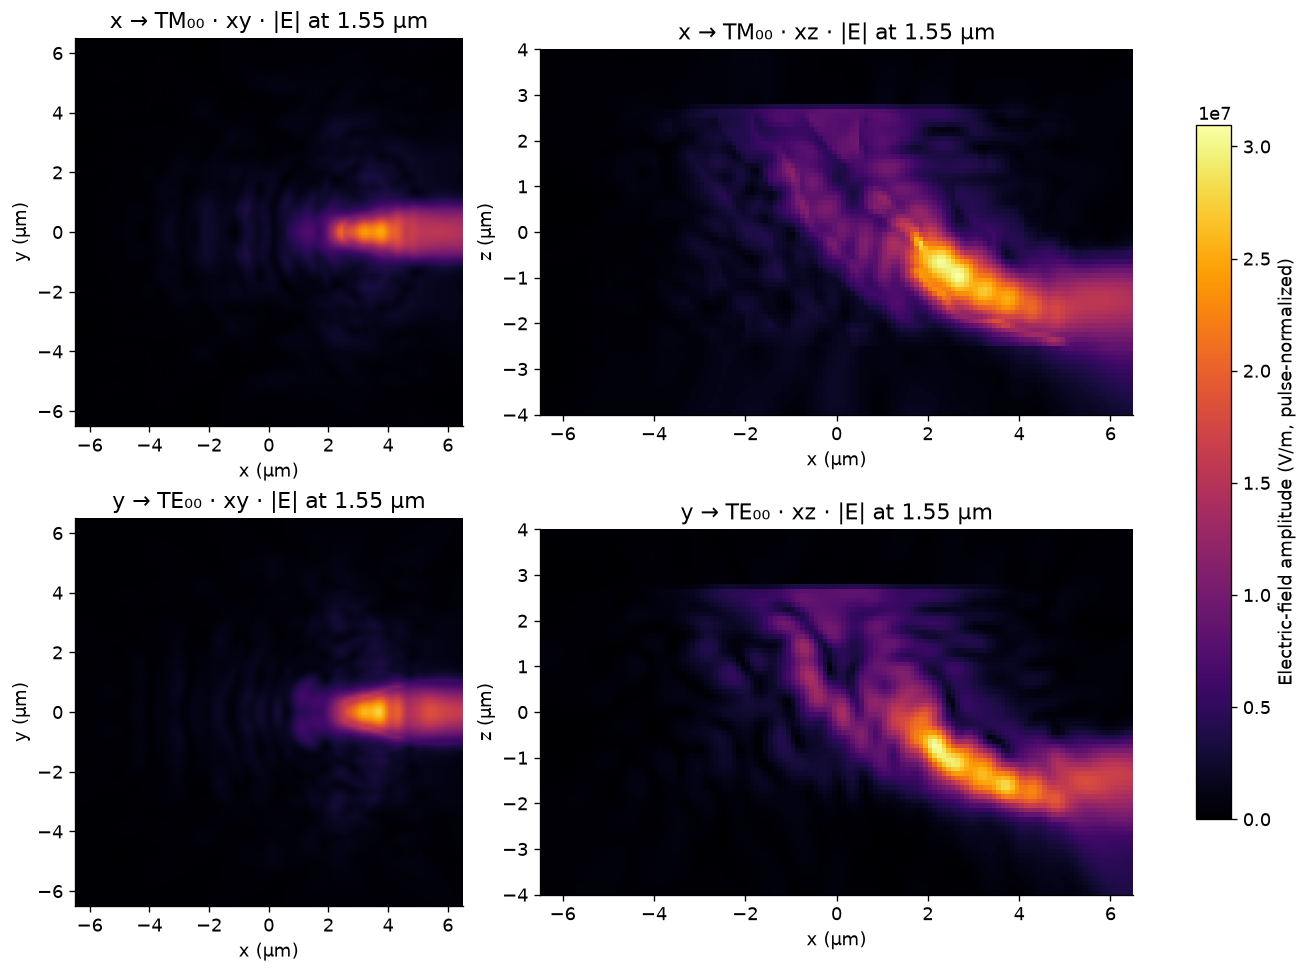

In [8]:
field_maps = [[np.sqrt(sum(abs(result[name].get_dft_component(component).reshape(-1))**2
                           for component in ("Ex", "Ey", "Ez")))
               for name in ("xy", "xz")] for result in validation]
# Frequency-domain acquisitions store flattened common-plane samples.
for pair, result in zip(field_maps, validation):
    for index, name in enumerate(("xy", "xz")):
        sampled = result[name].sample_region
        plane_axes = ("y", "x") if name == "xy" else ("z", "x")
        shape = tuple(sampled.intervals[axis].stop - sampled.intervals[axis].start for axis in plane_axes)
        pair[index] = pair[index].reshape(shape).squeeze()
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
norm = Normalize(0, max(float(field.max()) for pair in field_maps for field in pair))
for row, pair in enumerate(field_maps):
    for column, field in enumerate(pair):
        extent = (-6.5, 6.5, -6.5, 6.5) if column == 0 else (-6.5, 6.5, -4, 4)
        image = axes[row, column].imshow(field, origin="lower", extent=extent, cmap="inferno", norm=norm)
        axes[row, column].set(xlabel="x (µm)", ylabel=("y (µm)" if column == 0 else "z (µm)"),
                             title=f"{['x → TM₀₀', 'y → TE₀₀'][row]} · {['xy', 'xz'][column]} · |E| at 1.55 µm")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="Electric-field amplitude (V/m, pulse-normalized)")
fig.savefig(output_dir / "fields.png");

## Check run duration and the thresholded geometry

A continuous-density optimum can use intermediate material values. Thresholding may change performance substantially. The binary check below runs the ordinary solver with a thresholded density through the same material map; it does not claim a manufacturable mesh or mesh convergence. Layered polygon export is available with `experiments[0].export_design(params, beta=final_beta, mode="pixel_exact")` for independent geometry rasterization.

Before reporting a final device, repeat with smaller **FDTD** steps (the reference density pixels are already 50 nm), longer run times, and the exported binary geometry. The coarse `smoke` profile is an execution check only.

In [9]:
long_ce, binary_ce = [], []
physical_density = np.asarray(region.material_density(params, beta=final_beta))
# Density is already mirrored; skip transforms so the thresholded values stay binary.
binary_region = region.updated_copy(transformations=[])
for experiment in experiments:
    continuous = experiment.to_simulation(params, beta=final_beta)
    longer = continuous.updated_copy(run_time=1.5*run_time).run(backend="jax", performance=False)
    long_ce.append(float(abs(longer.mode("output").amps.sel(direction="+", mode_index=0).values[0])**2 / longer.launched_power(0)))
    binary = experiment.updated_copy(design_region=binary_region).to_simulation((physical_density >= 0.5).astype(np.float32))
    result = binary.run(backend="jax", performance=False)
    binary_ce.append(float(abs(result.mode("output").amps.sel(direction="+", mode_index=0).values[0])**2 / result.launched_power(0)))
long_ce, binary_ce = np.array(long_ce), np.array(binary_ce)
relative_duration_change = np.max(abs(long_ce-final_ce) / np.maximum(final_ce, 1e-8))
print(f"50% longer run: x→TM {long_ce[0]:.2%}, y→TE {long_ce[1]:.2%}; "
      f"maximum relative change {relative_duration_change:.2%}")
print(f"Thresholded density: x→TM {binary_ce[0]:.2%}, y→TE {binary_ce[1]:.2%}")
assert relative_duration_change < 0.02, "Increase run_time and repeat before trusting the objective"
np.savez_compressed(output_dir / "checks.npz", continuous_ce=final_ce, longer_ce=long_ce,
                    binary_ce=binary_ce, gradient_relative_error=relative_error,
                    duration_relative_change=relative_duration_change)
print(f"Numerical arrays and figures saved to {output_dir.resolve()}")

50% longer run: x→TM 69.95%, y→TE 71.82%; maximum relative change 0.00%
Thresholded density: x→TM 70.14%, y→TE 71.75%
Numerical arrays and figures saved to /home/quentinwach/beamz/beamz-volumetric-grating/results/polarization_insensitive_grating/reference


The saved outputs above are BeamZ calculations for the printed profile. They demonstrate volumetric optimization and the two-channel workflow. Mesh convergence, minimum printable features, and structural integrity require additional validation before fabrication.